# XGBoost Without the Flood Input

CRISP-DM phase: Modelling + Evaluation

**The short story.** The first XGBoost model (`XGBoost.ipynb`) uses `flood_this_month` ("was there already a recorded flood in this county this month?") as an input, and it is the most important one. That is fine for a backtest, where we know the flood records. It is not fine for a real forecast: nobody publishes flood records live, so when we forecast next month we do not know this input and had to set it to 0. The model was never trained to work that way.

So here we **train a new XGBoost model that does not use `flood_this_month` at all**. We also drop five features that the first model never used (importance exactly 0), and we check that dropping them changes nothing. Then we compare the new model with the old one, in the way the old one is really used live, on the same test years (2020 to 2024).

The notebook follows `XGBoost.ipynb` step by step (same data, same split, same cross-validation, same settings, same way of choosing the Watch and Warning thresholds). Only three things change:

1. `flood_this_month` is removed from the features.
2. Five features with zero importance are removed (checked in two runs: with and without them).
3. The cross-validation drops a few training rows that would leak information (explained in Section 2).

`XGBoost.ipynb` and the saved model `models/xgboost.joblib` are not touched. The new model is saved as `models/xgboost_no_flood.joblib`.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve

### 1.2 Loading the Data, the Current Model and Its Settings

In [2]:
#the same training and test sets as XGBoost.ipynb (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

#the current model (with flood_this_month) and its saved settings and thresholds
current_model = joblib.load('../models/xgboost.joblib')
with open('../models/xgboost_settings.json') as settings_file:
    settings = json.load(settings_file)
print(settings['best_params'])
print('watch', settings['watch_threshold'], 'warning', settings['warning_threshold'])

{'subsample': 1.0, 'scale_pos_weight': 10.19047619047619, 'reg_lambda': 5, 'n_estimators': 400, 'min_child_weight': 50, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
watch 0.34251049160957336 warning 0.4373789131641388


### 1.3 Features and Target

The target is the same as before: `flood_next_month`. The feature lists are:

- **25 features**: what the current model uses.
- **24 features**: the 25 without `flood_this_month`.
- **19 features**: the 24 without the five features that have an importance of exactly 0 in the current model. The current model never used them in any of its trees, so removing them should not change anything. We check this by running both the 24 and the 19 feature versions.

In [3]:
#columns that are not features: keys and target
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month']
all_features = list(current_model.feature_names_in_)
y_train = train['flood_next_month']
y_test = test['flood_next_month']

#the five features that the current model never used
zero_importance = [name for name, value in zip(current_model.feature_names_in_, current_model.feature_importances_) if value == 0]
print('never used by the current model:', zero_importance)

#the two new feature lists
features_24 = [name for name in all_features if name != 'flood_this_month']
features_19 = [name for name in features_24 if name not in zero_importance]
print(len(all_features), len(features_24), len(features_19))
print(features_19)

never used by the current model: [np.str_('area_km2'), np.str_('lc_tree'), np.str_('lc_bare'), np.str_('pct_occasional_water'), np.str_('pop_density')]
25 24 19
[np.str_('rain_mm'), np.str_('rain_lag1'), np.str_('rain_lag2'), np.str_('rain_pct_normal'), np.str_('neighbour_rain'), np.str_('ndvi_pct_normal'), np.str_('oni'), np.str_('dmi'), np.str_('month_sin'), np.str_('month_cos'), np.str_('soil_moisture_l1'), np.str_('runoff_rank'), np.str_('discharge_rank'), np.str_('pct_flat'), np.str_('lc_grass'), np.str_('lc_crop'), np.str_('pct_within_1km_river'), np.str_('pct_water'), np.str_('county_flood_rate')]


In [4]:
#every feature of the training file is either a feature or one of the not_features
print(sorted(set(train.columns) - set(not_features) - set(all_features)))
print(train.shape, int(y_train.sum()), test.shape, int(y_test.sum()))

[]
(9870, 30) 882 (2820, 30) 144


#### Observation

The training set has 9,870 rows with 882 floods and the test set has 2,820 rows with 144 floods, as in `XGBoost.ipynb`. The current model uses 25 features. The five that it never used (importance exactly 0) are `area_km2`, `lc_tree`, `lc_bare`, `pct_occasional_water` and `pop_density`. Without them and without `flood_this_month` we have 19 features. The check shows that every column of the training file is either one of the 25 features or a key/target column, so nothing was lost by accident.

## 2. Cross-Validation, and a Small Leak That We Remove

The cross-validation is the same as in `XGBoost.ipynb`: 5 folds that keep whole years together (`GroupKFold`). It is used to choose the thresholds, so the thresholds are measured on years that the model did not see.

**The small leak.** Each row is one county in one month, and its target is the flood in the *next* month. A training row from December of the year before a validation year has a target in January of the validation year. So the model learns from an answer that belongs to the validation year. The leak is small (one month at the start of each validation year), but it makes the cross-validation a little too optimistic, and the thresholds are chosen on it. The same small leak exists in `XGBoost.ipynb`, which we left as it was.

In the new model we **purge** these rows: for each fold, we drop the training rows whose next-month target falls in a validation year.

In [5]:
#the number of the month, and the year of the month that the target is about (the next month)
month_number = train['year'] * 12 + train['month'] - 1
target_year = (month_number + 1) // 12

#the usual 5 folds that keep whole years together
plain_splits = list(GroupKFold(n_splits=5).split(train, y_train, groups=train['year']))

#the same folds, with the leaking training rows dropped
purged_splits = []
for fold, (train_idx, val_idx) in enumerate(plain_splits, start=1):
    val_years = train['year'].iloc[val_idx].unique()
    leaking = target_year.iloc[train_idx].isin(val_years).to_numpy()
    purged_splits.append((train_idx[~leaking], val_idx))
    print('fold', fold, 'validation years', sorted(val_years), 'training rows dropped', int(leaking.sum()))

fold 1 validation years [np.int64(2004), np.int64(2009), np.int64(2014), np.int64(2019)] training rows dropped 188


fold 2 validation years [np.int64(2003), np.int64(2008), np.int64(2013), np.int64(2018)] training rows dropped 188
fold 3 validation years [np.int64(2002), np.int64(2007), np.int64(2012), np.int64(2017)] training rows dropped 141
fold 4 validation years [np.int64(2006), np.int64(2011), np.int64(2016)] training rows dropped 141
fold 5 validation years [np.int64(2005), np.int64(2010), np.int64(2015)] training rows dropped 141


#### Observation

In every fold, the training rows from December of the year before each validation year are dropped: 47 counties for each validation year that follows a training year. That is 188 rows in folds 1 and 2, and 141 in folds 3, 4 and 5 (fold 3 starts with 2002, which has no year before it in the data, and folds 4 and 5 have only three validation years). It is a small share of the 9,870 training rows, but the next section shows that it is not nothing.

## 3. Settings

We use the best settings that the randomized search of `XGBoost.ipynb` found (they are saved in `models/xgboost_settings.json`). We do not search again. This keeps the comparison clean: only the features change.

In [6]:
#the saved best settings of the current model
params = settings['best_params']
params

{'subsample': 1.0,
 'scale_pos_weight': 10.19047619047619,
 'reg_lambda': 5,
 'n_estimators': 400,
 'min_child_weight': 50,
 'max_depth': 3,
 'learning_rate': 0.01,
 'colsample_bytree': 1.0}

## 4. Training the New Models

For each of the two feature lists (24 and 19 features) we do the same steps as in `XGBoost.ipynb`:

1. PR-AUC in the purged cross-validation.
2. Out-of-fold flood probabilities (every row predicted by a model that did not see its year).
3. The two thresholds. **Watch** is the highest threshold with an out-of-fold recall of at least 0.80, **Warning** the highest with a recall of at least 0.70.
4. The final model, fitted on the whole training set.

In [7]:
#the two runs: the feature list and, after the loop, everything that came out of it
feature_sets = {'24 features': features_24, '19 features': features_19}
runs = {}
for name, columns in feature_sets.items():
    model = XGBClassifier(random_state=42, n_jobs=1, **params)
    cv_scores = cross_validate(model, train[columns], y_train, cv=purged_splits, scoring='average_precision')
    oof_prob = cross_val_predict(model, train[columns], y_train, cv=purged_splits, method='predict_proba')[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
    watch_cut = thresholds[recall[:-1] >= 0.80].max()
    warning_cut = thresholds[recall[:-1] >= 0.70].max()
    model.fit(train[columns], y_train)
    runs[name] = {'model': model, 'columns': columns, 'oof_prob': oof_prob, 'cv_pr_auc': cv_scores['test_score'],
                  'watch': watch_cut, 'warning': warning_cut}
    print(name, '| cv pr-auc', cv_scores['test_score'].round(3), 'mean', cv_scores['test_score'].mean().round(3),
          '| watch', round(watch_cut, 4), 'warning', round(warning_cut, 4))

24 features | cv pr-auc [0.12  0.215 0.169 0.296 0.327] mean 0.226 | watch 0.3434 warning 0.4225


19 features | cv pr-auc [0.121 0.216 0.17  0.304 0.333] mean 0.229 | watch 0.3431 warning 0.4219


In [8]:
#out-of-fold recall, precision and share of months flagged at the two thresholds
oof_rows = []
for name, run in runs.items():
    for level in ['watch', 'warning']:
        pred = (run['oof_prob'] >= run[level]).astype(int)
        oof_rows.append({'model': name, 'level': level, 'threshold': run[level], 'oof recall': recall_score(y_train, pred),
                         'oof precision': precision_score(y_train, pred), 'share of months flagged': pred.mean(), 'alerts': int(pred.sum())})
pd.DataFrame(oof_rows).round(3)

,model,level,threshold,oof recall,oof precision,share of months flagged,alerts
0,24 features,watch,0.343,0.800,0.150,0.476,4694
1,24 features,warning,0.423,0.701,0.172,0.364,3594
2,19 features,watch,0.343,0.800,0.150,0.476,4694
3,19 features,warning,0.422,0.701,0.172,0.364,3595


In [9]:
#how much the purge changes the thresholds: the 19-feature model with the plain (leaking) folds
plain_prob = cross_val_predict(XGBClassifier(random_state=42, n_jobs=1, **params), train[features_19], y_train, cv=plain_splits, method='predict_proba')[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, plain_prob)
print('plain folds  watch', round(thresholds[recall[:-1] >= 0.80].max(), 4), 'warning', round(thresholds[recall[:-1] >= 0.70].max(), 4))
print('purged folds watch', round(runs['19 features']['watch'], 4), 'warning', round(runs['19 features']['warning'], 4))
print('cv pr-auc plain', cross_validate(XGBClassifier(random_state=42, n_jobs=1, **params), train[features_19], y_train, cv=plain_splits, scoring='average_precision')['test_score'].mean().round(4),
      'purged', runs['19 features']['cv_pr_auc'].mean().round(4))

plain folds  watch 0.3557 warning 0.4463
purged folds watch 0.3431 warning 0.4219


cv pr-auc plain 0.2404 purged 0.2288


#### Observation

The 24-feature and 19-feature models are almost the same: cross-validation PR-AUC of 0.226 and 0.229, Watch thresholds of 0.343 and 0.343, Warning thresholds of 0.423 and 0.422, and the same out-of-fold recall (0.800 and 0.701), precision (0.150 and 0.172) and share of months flagged. This confirms that the five dropped features did nothing, as their importance of 0 said.

Compared with the current model the cross-validation looks much weaker: the PR-AUC is 0.229, against 0.476 for the current model. That is expected, because the current model could use `flood_this_month` (a flood this month is a strong sign of a flood next month). At the same out-of-fold recall of 0.80 the new model flags 47.6% of the training months and has a precision of 0.150, against 41.8% and 0.171 for the current model. The new model has to raise more alerts to find the same share of floods.

The purge matters: with the plain folds the thresholds would have been 0.356 (Watch) and 0.446 (Warning) and the PR-AUC 0.240. With the purged folds they are 0.343 and 0.422, and the PR-AUC is 0.229. So the small leak made the cross-validation a little too optimistic and the thresholds a little too high. The new model uses the purged numbers.

## 5. Comparison on the Test Set (2020 to 2024)

Both thresholds were fixed in Section 4, before the test set is used. The test set is scored for these models:

1. **Current model, real `flood_this_month`**: the backtest as in `XGBoost.ipynb`. This is not possible live, because the flood records are not known.
2. **Current model, `flood_this_month` forced to 0**: what the live forecast did so far.
3. **Current model, forced to 0, plus the stand-ins for the ERA5 and GloFAS inputs**: exactly the inputs that the live forecast has (soil moisture = the training mean of the county and month, the two ranks = 0.5).
4. **New model, 19 features**, and **4b, the 24 feature version**, to check that the five dropped features change nothing.

The three rows of the current model use its saved thresholds (0.3425 and 0.4374). The new models use their own thresholds from Section 4. Because the thresholds are different, the number of alerts is different, so we also compare the **recall at the same number of alerts**.

In [10]:
#the test inputs of the current model: real, flood_this_month forced to 0, and forced to 0 with the stand-ins
x_real = test[all_features]
x_zero = x_real.assign(flood_this_month=0)
soil_mean = train.groupby(['pcode', 'month'])['soil_moisture_l1'].mean().rename('soil_mean').reset_index()
x_standin = x_zero.copy()
x_standin['soil_moisture_l1'] = test[['pcode', 'month']].merge(soil_mean, on=['pcode', 'month'], how='left')['soil_mean'].to_numpy()
x_standin['runoff_rank'] = 0.5
x_standin['discharge_rank'] = 0.5
print(x_standin[['soil_moisture_l1', 'runoff_rank', 'discharge_rank']].isna().sum().sum(), 'missing stand-in values')

0 missing stand-in values


In [11]:
#flood probabilities of every model on the test set, with the two thresholds of each
test_models = {
    '1. current model, real flood_this_month': (current_model.predict_proba(x_real)[:, 1], settings['watch_threshold'], settings['warning_threshold']),
    '2. current model, flood_this_month = 0': (current_model.predict_proba(x_zero)[:, 1], settings['watch_threshold'], settings['warning_threshold']),
    '3. current model, = 0 and stand-ins': (current_model.predict_proba(x_standin)[:, 1], settings['watch_threshold'], settings['warning_threshold']),
    '4. new model, 19 features': (runs['19 features']['model'].predict_proba(test[features_19])[:, 1], runs['19 features']['watch'], runs['19 features']['warning']),
    '4b. new model, 24 features': (runs['24 features']['model'].predict_proba(test[features_24])[:, 1], runs['24 features']['watch'], runs['24 features']['warning'])}

#the calendar baseline: the flood rate of the month in the training years, flagged when above the overall rate (as in XGBoost.ipynb)
month_rate = train.groupby('month')['flood_next_month'].mean()
calendar_prob = test['month'].map(month_rate).to_numpy()
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

#recall, precision and alerts at both levels, and the pr-auc and roc-auc (they do not need a threshold)
table_rows = []
for name, (prob, watch_cut, warning_cut) in test_models.items():
    watch_pred = (prob >= watch_cut).astype(int)
    warning_pred = (prob >= warning_cut).astype(int)
    table_rows.append({'model': name, 'watch recall': recall_score(y_test, watch_pred), 'watch precision': precision_score(y_test, watch_pred),
                       'watch alerts': int(watch_pred.sum()), 'warning recall': recall_score(y_test, warning_pred),
                       'warning precision': precision_score(y_test, warning_pred), 'warning alerts': int(warning_pred.sum()),
                       'pr-auc': average_precision_score(y_test, prob), 'roc-auc': roc_auc_score(y_test, prob)})
table_rows.append({'model': 'calendar baseline', 'watch recall': recall_score(y_test, calendar_pred), 'watch precision': precision_score(y_test, calendar_pred),
                   'watch alerts': int(calendar_pred.sum()), 'pr-auc': average_precision_score(y_test, calendar_prob), 'roc-auc': roc_auc_score(y_test, calendar_prob)})
comparison = pd.DataFrame(table_rows).set_index('model')
comparison.round(3)

,watch recall,watch precision,watch alerts,warning recall,warning precision,warning alerts,pr-auc,roc-auc
model,,,,,,,,
"1. current model, real flood_this_month",0.979,0.120,1172,0.903,0.161,806.0,0.374,0.904
"2. current model, flood_this_month = 0",0.882,0.112,1130,0.757,0.147,744.0,0.159,0.814
"3. current model, = 0 and stand-ins",0.882,0.110,1155,0.778,0.144,777.0,0.165,0.818
"4. new model, 19 features",0.944,0.097,1399,0.875,0.114,1103.0,0.139,0.808
"4b. new model, 24 features",0.944,0.097,1401,0.882,0.116,1097.0,0.138,0.809
calendar baseline,0.847,0.087,1410,NaN,NaN,NaN,0.141,0.762


#### Observation

What the table says, in plain words:

- **The forced-to-0 model (2) is what the live forecast used.** It finds 88% of the floods at Watch and 76% at Warning, and its PR-AUC falls from 0.374 (real input) to 0.159. Adding the stand-ins (3) changes almost nothing (88% and 78%, PR-AUC 0.165), which agrees with what we found before.
- **The new model (4) finds more floods at both levels: 94% at Watch and 88% at Warning.** But it also raises many more alerts: 1,399 Watch alerts against 1,130, and 1,103 Warning alerts against 744. The reason is that its thresholds were set on cross-validation *without* `flood_this_month`, to reach 80% and 70% recall, while the thresholds of the current model were set when the input was available, so with the input forced to 0 its alerts become rarer and its recall lower. The new model gets its higher recall by alerting more, so the recalls cannot be compared by themselves. Precision shows the cost: 0.097 against 0.112 at Watch, and 0.114 against 0.147 at Warning.
- **Ranking quality, which does not depend on a threshold, is a bit worse in the new model:** PR-AUC 0.139 against 0.159 for the forced-to-0 model (ROC-AUC 0.808 against 0.814). Its PR-AUC is about the same as that of the calendar baseline (0.141), which only knows the month of the year. The forced-to-0 model is a little above the calendar baseline (0.159).
- The 24-feature version (4b) is the same as the 19-feature version, so the five dropped features really change nothing.

With only 144 floods in the test set, differences of about 0.02 in PR-AUC are small, and we did not test whether they are real. What is clear is that the new model is not better than the forced-to-0 model at ranking counties, and that none of the models without `flood_this_month` is far above the calendar baseline.

### 5.1 Recall at the Same Number of Alerts

A model that raises more alerts will usually find more floods. To compare fairly, we give every model the same number of alerts: the number of Watch alerts (and of Warning alerts) of the new 19-feature model, and we ask how many floods each model finds with its highest-risk rows. For the calendar baseline, many rows have the same score, so the tied rows are counted by their average (as if the tie were broken at random).

In [12]:
#recall when a model flags its n highest-risk rows (ties are shared out evenly)
def recall_at_top(prob, y, n):
    prob = np.asarray(prob)
    y = np.asarray(y)
    cut = np.sort(prob)[::-1][n - 1]
    above = prob > cut
    tied = prob == cut
    found = y[above].sum() + y[tied].sum() * (n - above.sum()) / tied.sum()
    return found / y.sum()

n_watch = test_models['4. new model, 19 features'][0] >= test_models['4. new model, 19 features'][1]
n_warning = test_models['4. new model, 19 features'][0] >= test_models['4. new model, 19 features'][2]
n_watch, n_warning = int(n_watch.sum()), int(n_warning.sum())
print('alerts used for the comparison: watch', n_watch, 'warning', n_warning)

matched = {}
for name, (prob, watch_cut, warning_cut) in test_models.items():
    matched[name] = {'recall at the watch alerts': recall_at_top(prob, y_test, n_watch), 'recall at the warning alerts': recall_at_top(prob, y_test, n_warning)}
matched['calendar baseline'] = {'recall at the watch alerts': recall_at_top(calendar_prob, y_test, n_watch), 'recall at the warning alerts': recall_at_top(calendar_prob, y_test, n_warning)}
pd.DataFrame(matched).T.round(3)

alerts used for the comparison: watch 1399 warning 1103


,recall at the watch alerts,recall at the warning alerts
"1. current model, real flood_this_month",0.986,0.972
"2. current model, flood_this_month = 0",0.924,0.868
"3. current model, = 0 and stand-ins",0.931,0.875
"4. new model, 19 features",0.944,0.875
"4b. new model, 24 features",0.944,0.882
calendar baseline,0.836,0.618


#### Observation

With the same number of alerts the picture is much closer. At the 1,399 Watch alerts of the new model, the new model finds 94.4% of the floods and the forced-to-0 model 92.4%. At the 1,103 Warning alerts, 87.5% against 86.8%. So the new model is slightly better or equal at the same number of alerts, and its apparent advantage in the table above came mostly from alerting more. Both are clearly above the calendar baseline (83.6% and 61.8%), which is the useful part: the model does add something beyond the season, mainly at the Warning level. The model with the real `flood_this_month` is at 98.6% and 97.2%, so what is lost by not knowing the flood records is about 6 to 10 points of recall at the same number of alerts.

### 5.2 Alerts per Year

How many alerts does each model raise in each test year? (There are 47 counties and 12 months, so 564 county-months per year.) The last row is the number of floods recorded the month after the forecast month in that year, for reference.

In [13]:
#alerts per year at the watch level and at the warning level, and the floods of each year
watch_per_year = pd.DataFrame({name: pd.Series(prob >= watch_cut).groupby(test['year'].to_numpy()).sum() for name, (prob, watch_cut, warning_cut) in test_models.items()})
warning_per_year = pd.DataFrame({name: pd.Series(prob >= warning_cut).groupby(test['year'].to_numpy()).sum() for name, (prob, watch_cut, warning_cut) in test_models.items()})
watch_per_year['floods recorded'] = y_test.groupby(test['year']).sum()
warning_per_year['floods recorded'] = y_test.groupby(test['year']).sum()
print('Watch alerts per year')
display(watch_per_year)
print('Warning alerts per year')
display(warning_per_year)

Watch alerts per year


,"1. current model, real flood_this_month","2. current model, flood_this_month = 0","3. current model, = 0 and stand-ins","4. new model, 19 features","4b. new model, 24 features",floods recorded
2020,271,253,257,359,360,39
2021,247,240,244,261,259,30
2022,94,92,95,133,138,3
2023,338,337,344,367,365,31
2024,222,208,215,279,279,41


Warning alerts per year


,"1. current model, real flood_this_month","2. current model, flood_this_month = 0","3. current model, = 0 and stand-ins","4. new model, 19 features","4b. new model, 24 features",floods recorded
2020,174,150,154,282,281,39
2021,143,128,138,190,189,30
2022,28,25,31,69,69,3
2023,275,273,278,326,324,31
2024,186,168,176,236,234,41


#### Observation

The new model raises more alerts in every year, especially at the Warning level (282 against 150 in 2020, 190 against 128 in 2021, 69 against 25 in 2022, 326 against 273 in 2023 and 236 against 168 in 2024). 2022 is the clearest false-alarm year: only 3 floods were recorded, and the new model still raised 133 Watch alerts (24% of the 564 county-months). The numbers of alerts of the current model do not move much when the input is forced to 0 (for example 253 against 271 Watch alerts in 2020), so forcing the input to 0 mostly made the model less able to find floods, not more alarmed.

## 6. Which Features Does the New Model Use?

Two kinds of importance, and **each chart says which one it shows**. They answer different questions, so they can disagree.

- **Gain importance** (from the trees): how much each feature improved the trees' splits, as a share of the total. It describes how the model was built.
- **Permutation importance** (from the test set): we shuffle one feature in the test set, so it carries no information, and see how much the model gets worse. We measure the drop in recall at the Watch threshold (fixed), and also the drop in PR-AUC, because shuffling can change the number of alerts and recall alone can mislead. It describes how much the predictions on the test years depend on the feature.

**A warning about rainfall.** The five rainfall features (`rain_mm`, `rain_lag1`, `rain_lag2`, `rain_pct_normal`, `neighbour_rain`) are strongly correlated: they all describe the same rain. When features are correlated, the model shares the credit between them, so each one looks weak alone, and shuffling one barely hurts because the others still carry the information. So we also show the **combined** importance of groups of related features (shuffling the whole group together).

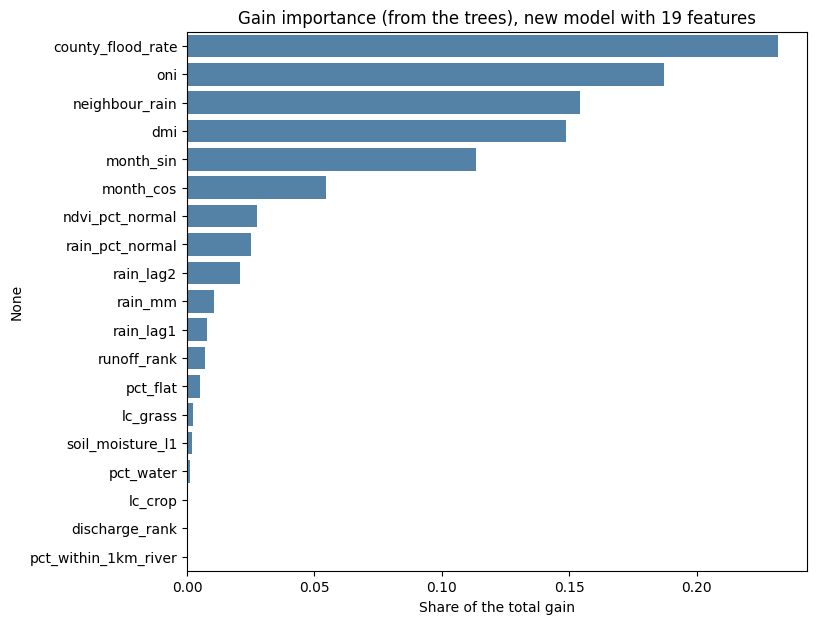

county_flood_rate       0.232
oni                     0.187
neighbour_rain          0.154
dmi                     0.149
month_sin               0.113
month_cos               0.054
ndvi_pct_normal         0.027
rain_pct_normal         0.025
rain_lag2               0.021
rain_mm                 0.010
rain_lag1               0.008
runoff_rank             0.007
pct_flat                0.005
lc_grass                0.003
soil_moisture_l1        0.002
pct_water               0.001
lc_crop                 0.001
discharge_rank          0.000
pct_within_1km_river    0.000
dtype: float64

In [14]:
#the final 19-feature model and its test inputs
model_19 = runs['19 features']['model']
x_test_19 = test[features_19]
watch_19 = runs['19 features']['watch']

#gain importance: the total gain of every feature as a share of the total
booster_gain = pd.Series(model_19.get_booster().get_score(importance_type='total_gain'))
gain_share = (booster_gain / booster_gain.sum()).reindex(features_19).fillna(0).sort_values(ascending=False)
plt.figure(figsize=(8, 7))
sns.barplot(x=gain_share.values, y=gain_share.index, color='steelblue')
plt.xlabel('Share of the total gain')
plt.title('Gain importance (from the trees), new model with 19 features')
plt.show()
gain_share.round(3)

recall at the watch threshold before shuffling: 0.944 | pr-auc: 0.139


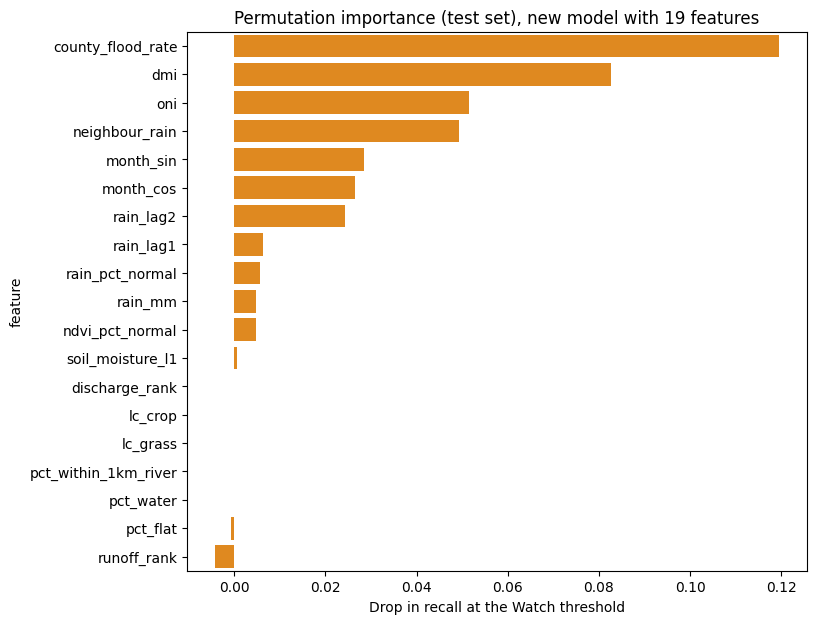

,recall drop,recall drop std,pr-auc drop
feature,,,
county_flood_rate,0.119,0.032,0.041
dmi,0.083,0.021,0.009
oni,0.051,0.018,-0.017
neighbour_rain,0.049,0.012,-0.004
month_sin,0.028,0.011,0.022
month_cos,0.026,0.013,-0.016
rain_lag2,0.024,0.008,0.007
rain_lag1,0.006,0.006,0.002
rain_pct_normal,0.006,0.006,-0.002


In [15]:
#permutation importance on the test set: shuffle one feature, 10 times, and see how much the model gets worse
rng = np.random.RandomState(42)
base_prob = model_19.predict_proba(x_test_19)[:, 1]
base_recall = recall_score(y_test, base_prob >= watch_19)
base_pr_auc = average_precision_score(y_test, base_prob)
perm_rows = []
for column in features_19:
    recall_drops = []
    pr_drops = []
    for repeat in range(10):
        shuffled = x_test_19.copy()
        shuffled[column] = rng.permutation(shuffled[column].to_numpy())
        prob = model_19.predict_proba(shuffled)[:, 1]
        recall_drops.append(base_recall - recall_score(y_test, prob >= watch_19))
        pr_drops.append(base_pr_auc - average_precision_score(y_test, prob))
    perm_rows.append({'feature': column, 'recall drop': np.mean(recall_drops), 'recall drop std': np.std(recall_drops), 'pr-auc drop': np.mean(pr_drops)})
perm = pd.DataFrame(perm_rows).sort_values('recall drop', ascending=False).set_index('feature')
print('recall at the watch threshold before shuffling:', round(base_recall, 3), '| pr-auc:', round(base_pr_auc, 3))
plt.figure(figsize=(8, 7))
sns.barplot(x=perm['recall drop'].values, y=perm.index, color='darkorange')
plt.xlabel('Drop in recall at the Watch threshold')
plt.title('Permutation importance (test set), new model with 19 features')
plt.show()
perm.round(3)

### 6.1 Groups of Related Features

The same two importances for groups of related features. For the permutation importance, all the features of a group are shuffled together (with the same shuffle, so they stay consistent with each other).

19 features in the groups, and all are used once: True


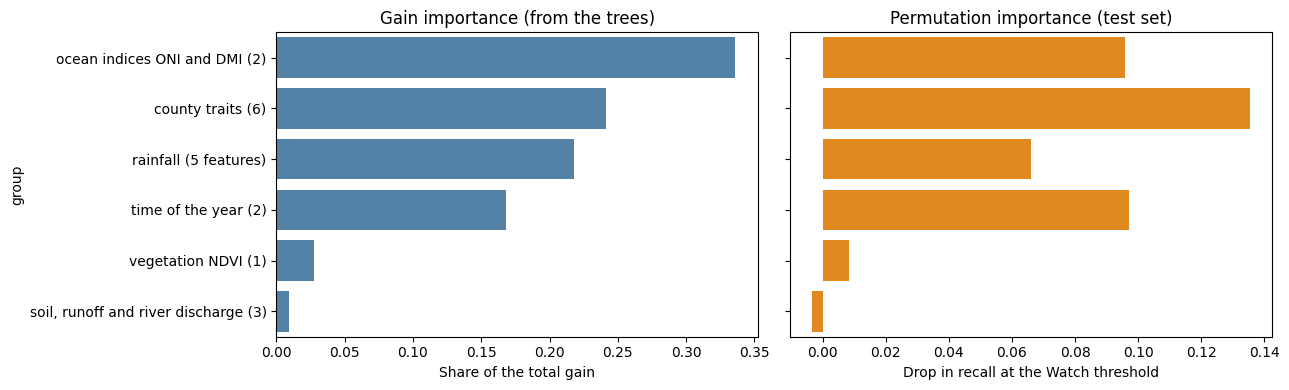

,gain share (trees),recall drop (permutation),pr-auc drop (permutation)
group,,,
ocean indices ONI and DMI (2),0.336,0.096,0.018
county traits (6),0.241,0.135,0.044
rainfall (5 features),0.218,0.066,-0.003
time of the year (2),0.168,0.097,0.017
vegetation NDVI (1),0.027,0.008,0.001
"soil, runoff and river discharge (3)",0.010,-0.003,-0.002


In [16]:
#groups of related features (together they are the 19 features)
groups = {'rainfall (5 features)': ['rain_mm', 'rain_lag1', 'rain_lag2', 'rain_pct_normal', 'neighbour_rain'],
          'ocean indices ONI and DMI (2)': ['oni', 'dmi'],
          'time of the year (2)': ['month_sin', 'month_cos'],
          'vegetation NDVI (1)': ['ndvi_pct_normal'],
          'soil, runoff and river discharge (3)': ['soil_moisture_l1', 'runoff_rank', 'discharge_rank'],
          'county traits (6)': ['county_flood_rate', 'pct_flat', 'pct_within_1km_river', 'lc_grass', 'lc_crop', 'pct_water']}
print(sum(len(cols) for cols in groups.values()), 'features in the groups, and all are used once:', sorted(sum(groups.values(), [])) == sorted(features_19))

group_rows = []
for group, columns in groups.items():
    recall_drops = []
    pr_drops = []
    for repeat in range(10):
        shuffled = x_test_19.copy()
        order = rng.permutation(len(shuffled))
        shuffled[columns] = shuffled[columns].to_numpy()[order]
        prob = model_19.predict_proba(shuffled)[:, 1]
        recall_drops.append(base_recall - recall_score(y_test, prob >= watch_19))
        pr_drops.append(base_pr_auc - average_precision_score(y_test, prob))
    group_rows.append({'group': group, 'gain share (trees)': gain_share[columns].sum(), 'recall drop (permutation)': np.mean(recall_drops), 'pr-auc drop (permutation)': np.mean(pr_drops)})
group_table = pd.DataFrame(group_rows).set_index('group').sort_values('gain share (trees)', ascending=False)

#two charts, one for each kind of importance
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.barplot(x=group_table['gain share (trees)'].values, y=group_table.index, color='steelblue', ax=axes[0])
axes[0].set_title('Gain importance (from the trees)')
axes[0].set_xlabel('Share of the total gain')
sns.barplot(x=group_table['recall drop (permutation)'].values, y=group_table.index, color='darkorange', ax=axes[1])
axes[1].set_title('Permutation importance (test set)')
axes[1].set_xlabel('Drop in recall at the Watch threshold')
plt.tight_layout()
plt.show()
group_table.round(3)

#### Observation

**Gain importance (from the trees).** The most used feature is `county_flood_rate` (23%), then `oni` (19%), `neighbour_rain` (15%), `dmi` (15%) and `month_sin` (11%). The three soil, runoff and river features carry about 1% together, and the vegetation feature 3%.

**Permutation importance (test set).** Shuffling `county_flood_rate` hurts most (recall at Watch drops by 12 points), then `dmi` (8 points), `oni` and `neighbour_rain` (5 points each). Two things stand out. First, the PR-AUC *rises* a little when `oni` or `month_cos` are shuffled (by 0.017 and 0.016 respectively). So in the test years the model's use of ONI helps it find floods (recall) but does not help it rank the counties, a sign that its dependence on ONI is not a clean signal. This matters for the live forecast, where ONI is at 2.46. Second, the soil, runoff and discharge features hardly matter, as before.

**The rainfall group.** The five rainfall features are weak one by one in the permutation chart (the drops are between 0.5 and 5 points), but together they carry 22% of the gain and shuffling them together costs 6.6 points of recall, which is more than any single rainfall feature suggests. The model shares the credit between them, so reading a single bar would underestimate the rain. Looking at the groups, the two ocean indices carry the most gain (34%) and the county traits (the 6 static features) 24%, with the time of the year at 17% and the rainfall at 22%. Everything the model knows about the weather of the month (rainfall, vegetation, soil) is less than what it knows from ocean indices, the season and the county itself.

## 7. Is the New Model Good Enough to Replace the Current One?

We decide with a rule that is written down before looking at the answer. The new 19-feature model replaces the current one in the live forecast if, on the test set, it is **at least as good as the current model with `flood_this_month` forced to 0** (model 2, which is what the live forecast used so far), on all three of:

- the recall at the Watch threshold is at least as high,
- the recall at the Warning threshold is at least as high,
- the PR-AUC is at least as high.

We also look at the stand-in version (model 3), which is the exact live input of the current model.

In [17]:
#the decision rule, written as code
new = comparison.loc['4. new model, 19 features']
forced = comparison.loc['2. current model, flood_this_month = 0']
standin = comparison.loc['3. current model, = 0 and stand-ins']
checks = {'watch recall': new['watch recall'] >= forced['watch recall'],
          'warning recall': new['warning recall'] >= forced['warning recall'],
          'pr-auc': new['pr-auc'] >= forced['pr-auc']}
print('new model against model 2 (forced to 0):')
for name, passed in checks.items():
    print(' ', name, round(new[name], 3), 'vs', round(forced[name], 3), '->', 'at least as good' if passed else 'worse')
print('new model against model 3 (forced to 0 + stand-ins): watch', round(new['watch recall'], 3), 'vs', round(standin['watch recall'], 3),
      '| warning', round(new['warning recall'], 3), 'vs', round(standin['warning recall'], 3), '| pr-auc', round(new['pr-auc'], 3), 'vs', round(standin['pr-auc'], 3))
replace_current = all(checks.values())
print('use the new model in the live forecast and the app:', replace_current)

new model against model 2 (forced to 0):
  watch recall 0.944 vs 0.882 -> at least as good
  warning recall 0.875 vs 0.757 -> at least as good
  pr-auc 0.139 vs 0.159 -> worse
new model against model 3 (forced to 0 + stand-ins): watch 0.944 vs 0.882 | warning 0.875 vs 0.778 | pr-auc 0.139 vs 0.165
use the new model in the live forecast and the app: False


#### Observation

**Decision: keep the current setup.** The new model is at least as good as the forced-to-0 model on the recall at Watch (0.944 against 0.882) and at Warning (0.875 against 0.757), but it is worse on the PR-AUC (0.139 against 0.159), and the rule needs all three. The recalls are higher mainly because the new model raises more alerts (Section 5.1), and the PR-AUC, which does not depend on the number of alerts, says that it ranks the county-months slightly worse. So the current model (with `flood_this_month` set to 0 in the live forecast, plus the manual entry and the stand-in pills) stays in `update_forecast.py` and the app. `models/xgboost_no_flood.joblib` is saved for the record, and the settings file says that it does not replace the current model.

This is a fair result to present: removing the input from the features did not rescue the live forecast, and it showed that most of what the model knows without the flood records is the season, the county and the ocean indices. One thing was not tried: the settings were chosen for the model *with* `flood_this_month`, and a new randomized search for the 19 features might do a little better. We kept the saved settings on purpose, so that only the features change.

## 8. Saving the Model

The 19-feature model and its settings are saved as new files. The current model files are not touched. The json file also keeps the feature list (the live forecast reads it), both thresholds, the cross-validation scores and the decision.

In [18]:
#saving the new model (the files of the current model are not touched)
joblib.dump(model_19, '../models/xgboost_no_flood.joblib', compress=3)

#the settings, features, both thresholds, the cross-validation scores and the test numbers as plain python values
run_19 = runs['19 features']
oof_watch = (run_19['oof_prob'] >= run_19['watch']).astype(int)
oof_warning = (run_19['oof_prob'] >= run_19['warning']).astype(int)
best_params = {name: (value.item() if hasattr(value, 'item') else value) for name, value in params.items()}
new_settings = {'model': 'XGBoost without flood_this_month',
                'features': features_19,
                'dropped_features': ['flood_this_month'] + zero_importance,
                'best_params': best_params,
                'cv': 'GroupKFold(5) on year, training rows whose next-month target falls in the validation year removed',
                'cv_pr_auc_mean': float(run_19['cv_pr_auc'].mean()),
                'cv_pr_auc_std': float(run_19['cv_pr_auc'].std()),
                'watch_threshold': float(run_19['watch']),
                'warning_threshold': float(run_19['warning']),
                'watch_recall_target': 0.80,
                'warning_recall_target': 0.70,
                'watch_oof_recall': float(recall_score(y_train, oof_watch)),
                'watch_oof_precision': float(precision_score(y_train, oof_watch)),
                'warning_oof_recall': float(recall_score(y_train, oof_warning)),
                'warning_oof_precision': float(precision_score(y_train, oof_warning)),
                'test_watch_recall': float(new['watch recall']),
                'test_watch_precision': float(new['watch precision']),
                'test_warning_recall': float(new['warning recall']),
                'test_warning_precision': float(new['warning precision']),
                'test_pr_auc': float(new['pr-auc']),
                'forced_to_0_test_watch_recall': float(forced['watch recall']),
                'forced_to_0_test_warning_recall': float(forced['warning recall']),
                'forced_to_0_test_pr_auc': float(forced['pr-auc']),
                'replaces_current_model_in_live_forecast': bool(replace_current)}
with open('../models/xgboost_no_flood_settings.json', 'w') as settings_file:
    json.dump(new_settings, settings_file, indent=2)
print(sorted(os.listdir('../models')))

['decision_tree.joblib', 'decision_tree_settings.json', 'logistic_regression.joblib', 'logistic_regression_settings.json', 'random_forest.joblib', 'random_forest_settings.json', 'xgboost.joblib', 'xgboost_no_flood.joblib', 'xgboost_no_flood_settings.json', 'xgboost_settings.json']


#### Observation

## 9. Summary of the Model Without the Flood Input

- **Why:** the live forecast cannot know `flood_this_month`, so it was set to 0, which the model was not trained for.
- **What we built:** an XGBoost model with 19 features (the 25, minus `flood_this_month` and five features that the current model never used), the same settings, split and thresholds method as `XGBoost.ipynb`, and a purged cross-validation (the small year-boundary leak removed).
- **The five dropped features:** no effect (24 and 19 features give the same results).
- **The purge:** removes a small leak, and it lowers the cross-validation PR-AUC from 0.240 to 0.229 and the thresholds from 0.356 and 0.446 to 0.343 and 0.422, so the old way was a little optimistic.
- **Test set (2020 to 2024):** the new model finds 94% of the floods at Watch and 88% at Warning, against 88% and 76% for the current model with the input forced to 0, but with 24% and 48% more alerts. At the same number of alerts the recall is about the same (94.4% against 92.4%, and 87.5% against 86.8%), and the PR-AUC is lower (0.139 against 0.159, with 0.141 for the calendar baseline).
- **Decision:** the new model is not at least as good on all three measures, so the current setup stays in the live forecast and the app.
- **What drives the model:** county, ocean indices, season and neighbouring rainfall. Rainfall is spread over five correlated features and is more important as a group than any single bar shows. The model does not use the soil, runoff and river features.
- **Limits:** only 144 test floods, and flood records after about mid-2024 are incomplete. A new search for the settings of the 19 features was not done.